# Версия 3, част 2 — къде са единиците и колко са? (детектор)

Класификаторът от `warcraft3_unit_crops.ipynb` познава изрязана единица, но не знае **къде** са единиците
на целия screenshot и **колко** са. Това е *object detection*: моделът дава по една рамка (box) за всяка
единица, заедно с класа ѝ. Броят на рамките = броят на единиците.

fast.ai няма готов детектор (в курса detection е само споменат), затова тук използваме **YOLO** от
пакета `ultralytics` — най-разпространеният детектор, също на PyTorch, с подобен стил: зареждаме
предварително обучен модел и го *дообучаваме* (transfer learning, както `fine_tune`).
Моделът е `yolo26s` (s = small, 10 милиона параметъра).

Рамките за обучението не са рисувани на ръка: в solo снимките знаем мястото на всяко копие спрямо
камерата и го пресмятаме със същата формула като в crop notebook-а.

In [1]:
from ultralytics import YOLO
from PIL import Image, ImageDraw
from pathlib import Path
import numpy as np, pandas as pd, shutil

BASE = Path('data/single_units')
YOLO_DATA = Path('data/yolo')
rows = pd.read_csv(BASE/'labels.csv')
excluded = pd.read_csv(BASE/'excluded.csv')
rows = rows[rows['split'].isin(['train','valid'])]
# frames excluded only because of the "No clear capture area" text are fine here: the text isn't a unit
warning = set(excluded.loc[excluded['reason'].str.contains('warning text'), 'fname'])
rows = rows[~rows['fname'].isin(set(excluded['fname']) - warning)]
vocab = sorted(rows['labels'].unique())
len(vocab), rows.groupby('split').size()

(48,
 split
 train    2781
 valid     167
 dtype: int64)

## Рамка на единица по позицията ѝ

`screen_box(x, y, zoom)`: x, y = мястото на единицата спрямо точката, над която е камерата
(в единици на картата), zoom = разстоянието на камерата. Числата F, CX, CY са измерени от снимките
(виж crop notebook-а). Рамката е по-висока нагоре, за да хване и летящите.
`solo_positions` пресмята x, y на копията точно както `dataset_trigger_single.j`.
За смесените сцени `capture.py` вече записва x, y, zoom на всяка единица в `data/units.csv`.

In [2]:
F, CX, CY = 908, 630, 286
COS, SIN = np.cos(np.radians(56)), np.sin(np.radians(56))

def screen_box(x, y, zoom):
    "(left, top, right, bottom) in pixels of a 1280x720 screenshot"
    depth = zoom + y * COS
    sx, sy, scale = CX + F * x / depth, CY - F * y * SIN / depth, F / depth
    return (sx - 175*scale, sy - 320*scale, sx + 175*scale, sy + 145*scale)

def solo_positions(r):
    offsetx = (r.position % 3 - 1) * 220.0          # same formulas as in dataset_trigger_single.j
    offsety = (r.position // 3 - 1) * 140.0 - 70.0
    return [(offsetx + (i - (r.copies - 1) / 2) * 340, offsety) for i in range(r.copies)]

def hide_worker_icon(img):
    "The idle-worker portrait (bottom left) hints at worker classes; hide it everywhere, also later in the app."
    img = img.copy()
    img.paste((0, 0, 0), (160, 465, 220, 525))
    return img

## Данни във формата на YOLO

YOLO иска папки `images/train`, `labels/train`, `images/val`, `labels/val`. За всяка снимка има `.txt`
файл с по един ред на единица: `клас x_център y_център ширина височина` (всичко като част от размера на
снимката, 0…1). Validation е отново цялата непозната карта `single-valid1`.

In [3]:
shutil.rmtree(YOLO_DATA, ignore_errors=True)
for r in rows.itertuples():
    split = 'val' if r.split == 'valid' else 'train'
    (YOLO_DATA/'images'/split).mkdir(parents=True, exist_ok=True)
    (YOLO_DATA/'labels'/split).mkdir(parents=True, exist_ok=True)
    hide_worker_icon(Image.open(BASE/'screens'/r.fname)).save(YOLO_DATA/'images'/split/r.fname, quality=95)
    lines = []
    for x, y in solo_positions(r):
        l, t, rr, b = screen_box(x, y, r.zoom)
        l, t, rr, b = max(l, 0), max(t, 0), min(rr, 1280), min(b, 720)
        lines.append(f'{vocab.index(r.labels)} {(l+rr)/2/1280:.5f} {(t+b)/2/720:.5f} {(rr-l)/1280:.5f} {(b-t)/720:.5f}')
    (YOLO_DATA/'labels'/split/(Path(r.fname).stem + '.txt')).write_text('\n'.join(lines))

yaml = f"path: {YOLO_DATA.resolve().as_posix()}\ntrain: images/train\nval: images/val\nnames:\n"
yaml += ''.join(f'  {i}: {name}\n' for i, name in enumerate(vocab))
(YOLO_DATA/'data.yaml').write_text(yaml)
print(len(list((YOLO_DATA/'images'/'train').iterdir())), 'train,', len(list((YOLO_DATA/'images'/'val').iterdir())), 'val')

2781 train, 167 val


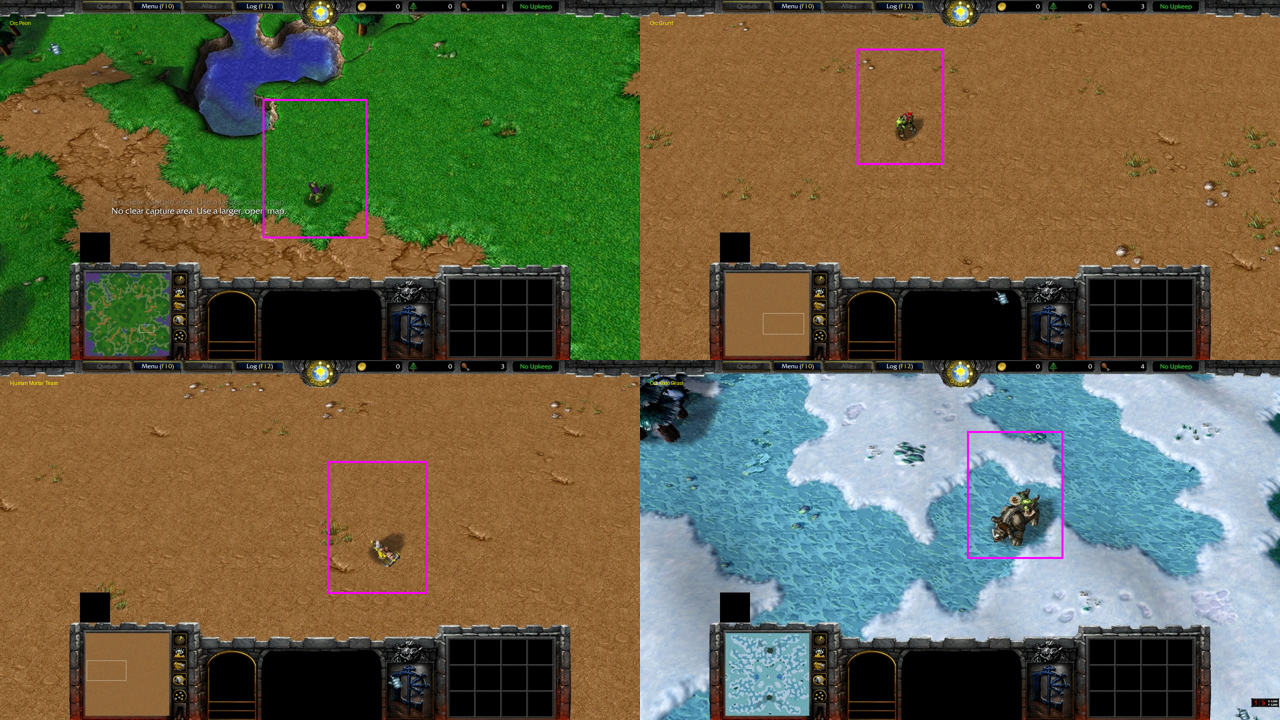

In [4]:
# check: draw the boxes of a few training images
sample = rows[rows['split'].eq('train')].sample(4, random_state=0)
sheet = Image.new('RGB', (1280, 720))
for k, r in enumerate(sample.itertuples()):
    img = Image.open(YOLO_DATA/'images'/'train'/r.fname)
    draw = ImageDraw.Draw(img)
    for x, y in solo_positions(r): draw.rectangle(screen_box(x, y, r.zoom), outline=(255, 0, 255), width=4)
    draw.text((20, 40), r.labels, fill=(255, 255, 0))
    sheet.paste(img.resize((640, 360)), ((k % 2) * 640, (k // 2) * 360))
sheet

## Обучение и аугментация

- `imgsz=1280` — пълната ширина на снимката: единиците са малки, не трябва да ги смаляваме.
- **mosaic** (вградено в YOLO): слепва 4 снимки в една. Така от solo снимките (един тип на снимка)
  получаваме сцени с **различни** единици заедно — точно това, което трябва да научи за смесените сцени.
- огледален образ хоризонтално (`fliplr=0.5`), без обръщане надолу и без въртене: камерата в играта е
  винаги под същия ъгъл.
- `scale=0.3` — ±30% размер, като различния zoom на камерата; `hsv_v=0.4` — ден/нощ.
- 30 епохи, batch 4 (batch 8 на 1280 не се побира в 11 GB на GTX 1080 Ti; ~7.5 мин. на епоха); YOLO пази най-добрата епоха (`best.pt`) по validation.

In [ ]:
model = YOLO('yolo26s.pt')
model.train(data=str(YOLO_DATA/'data.yaml'), imgsz=1280, epochs=30, batch=4, workers=4, cache=True,
            fliplr=0.5, flipud=0.0, degrees=0, mosaic=1.0, scale=0.3, hsv_v=0.4,
            project=str(Path('models').resolve()), name='detector', exist_ok=True, seed=42, plots=True)

Ако обучението спре по средата (на нашата GTX 1080 Ti веднъж: `CUDA error: an illegal instruction` в
епоха 26 — грешка на видеокартата, не на кода), то продължава от последната запазена епоха:
`YOLO('models/detector/weights/last.pt').train(resume=True)`.

Резултатите по епохи (validation = непознатата карта): precision = колко от намерените рамки са верни,
recall = колко от истинските единици са намерени, mAP50 = обща оценка на детектора (1.0 = идеален).

In [5]:
pd.read_csv('models/detector/results.csv')[['epoch', 'metrics/precision(B)', 'metrics/recall(B)',
                                            'metrics/mAP50(B)', 'metrics/mAP50-95(B)']]

,epoch,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B)
0,1,0.54129,0.24037,0.18696,0.12203
1,2,0.49400,0.54776,0.56972,0.32136
2,3,0.76474,0.60213,0.72541,0.50550
3,4,0.72158,0.73705,0.81106,0.50196
4,5,0.90809,0.81702,0.90950,0.58706
5,6,0.78749,0.84165,0.91371,0.69100
6,7,0.81950,0.91280,0.94222,0.64686
7,8,0.85296,0.92503,0.96009,0.67833
8,9,0.88457,0.92059,0.96466,0.72390
9,10,0.83278,0.93329,0.96791,0.72792


## Проверка: верен ли е броят и верни ли са всички единици?

За всяка validation снимка сравняваме списъка от предсказани единици с истинския (с повторенията):
- **брой верен** — толкова рамки, колкото са единиците;
- **изцяло вярна снимка** — същите единици и същият брой от всяка (това е целта „90%+“).

Прагът на увереност (`conf`) избираме по validation.

In [6]:
best = YOLO('models/detector/weights/best.pt')
val_rows = rows[rows['split'].eq('valid')]
results = best.predict([str(YOLO_DATA/'images'/'val'/f) for f in val_rows['fname']], imgsz=1280, conf=0.01,
                       verbose=False, stream=True)
preds = [(r.boxes.cls.int().tolist(), r.boxes.conf.tolist()) for r in results]

def scores(conf, truth):
    count_ok = exact = 0
    for (cls, cf), true in zip(preds, truth):
        guess = sorted(vocab[c] for c, p in zip(cls, cf) if p >= conf)
        count_ok += len(guess) == len(true)
        exact += guess == sorted(true)
    return count_ok / len(truth), exact / len(truth)

truth = [[r.labels] * r.copies for r in val_rows.itertuples()]
table = pd.DataFrame([(c, *scores(c, truth)) for c in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]],
                     columns=['conf', 'count correct', 'whole image correct'])
table

,conf,count correct,whole image correct
0,0.1,0.940120,0.928144
1,0.2,0.934132,0.928144
2,0.3,0.940120,0.934132
3,0.4,0.946108,0.934132
4,0.5,0.928144,0.922156
5,0.6,0.910180,0.904192
6,0.7,0.886228,0.880240


In [7]:
conf = float(table.loc[table['whole image correct'].idxmax(), 'conf'])
wrong = []
for r, (cls, cf) in zip(val_rows.itertuples(), preds):
    guess = sorted(vocab[c] for c, p in zip(cls, cf) if p >= conf)
    if guess != [r.labels] * r.copies: wrong.append((r.fname, [r.labels] * r.copies, guess))
print('conf', conf, '-', len(wrong), 'wrong images of', len(val_rows))
pd.DataFrame(wrong, columns=['image', 'truth', 'prediction'])

conf 0.3 - 11 wrong images of 167


,image,truth,prediction
0,single_single-valid1_20261021_204022_108407_00...,[Human Peasant],[Orc Grunt]
1,single_single-valid1_20261021_204022_108407_00...,[Human Spell Breaker],"[Human Spell Breaker, Troll Headhunter]"
2,single_single-valid1_20261021_204022_108407_00...,[Undead Gargoyle],[]
3,single_single-valid1_20261021_204022_108407_00...,[Undead Meat Wagon],"[Night Elf Wisp, Undead Meat Wagon]"
4,single_single-valid1_20261021_204022_108407_00...,[Undead Banshee],"[Night Elf Dryad, Undead Banshee]"
5,single_single-valid1_20261021_204022_108407_00...,[Human Peasant],[]
6,single_single-valid1_20261021_204022_108407_00...,[Troll Batrider],[]
7,single_single-valid1_20261021_204022_108407_00...,[Human Footman],[]
8,single_single-valid1_20261021_204022_108407_01...,[Night Elf Archer],[]
9,single_single-valid1_20261021_204022_108407_01...,[Undead Gargoyle],"[Night Elf Hippogryph, Undead Gargoyle]"


## Честен тест: смесените сцени от версия 2 (map4)

Детекторът е учен **само** на solo снимки. Map4 е друга карта със смесени сцени, понякога и сграда.
Там знаем кои единици има, но не колко (старият `labels.csv` пази само имената), затова сравняваме
**множеството** от имена — същата мярка като „изцяло познати“ във версия 2 (18%).

In [8]:
mixed = pd.read_csv('data/labels.csv')
mixed = mixed[mixed['fname'].str.startswith('map4_')]
found = []
for f in mixed['fname']:
    r = best.predict(hide_worker_icon(Image.open(Path('data/screens')/f)), imgsz=1280, conf=conf, verbose=False)[0]
    found.append(set(vocab[c] for c in r.boxes.cls.int().tolist()))
true_sets = [set(l.split(';')) for l in mixed['labels']]
exact = np.mean([f == t for f, t in zip(found, true_sets)])
recall = sum(len(f & t) for f, t in zip(found, true_sets)) / sum(len(t) for t in true_sets)
wrong_found = sum(len(f - t) for f, t in zip(found, true_sets))
print(f'map4: whole image correct {exact:.1%}, units found {recall:.1%}, wrong "found" {wrong_found}')

map4: whole image correct 37.2%, units found 67.3%, wrong "found" 230


## Детектор + класификатор

Две прости подобрения след детектора:
1. Понякога YOLO дава **две рамки на една единица** с различен клас. Ако две рамки се застъпват повече от
   половината (IoU > 0.5), пазим само по-сигурната.
2. Всяка останала рамка има същата форма като crop-овете от `warcraft3_unit_crops.ipynb`, затова можем
   да попитаме и fast.ai класификатора (98.8% на непознатата карта) коя е единицата.

In [9]:
from fastai.vision.all import load_learner, PILImage
classifier = load_learner('data/unit_crops/unit_classifier.pkl')

def iou(a, b):
    w = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    h = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    return w * h / ((a[2]-a[0]) * (a[3]-a[1]) + (b[2]-b[0]) * (b[3]-b[1]) - w * h)

def find_units(path, use_classifier=True):
    "List of unit names on a screenshot, one per unit."
    img = Image.open(path)
    r = best.predict(hide_worker_icon(img), imgsz=1280, conf=conf, verbose=False)[0]
    boxes, cls, cf = r.boxes.xyxy.tolist(), r.boxes.cls.int().tolist(), r.boxes.conf.tolist()
    keep = []
    for i in np.argsort(cf)[::-1]:                  # most confident first
        if all(iou(boxes[i], boxes[j]) < 0.5 for j in keep): keep.append(i)
    if not use_classifier or not keep: return [vocab[cls[i]] for i in keep]
    crops = [PILImage.create(np.array(img.crop(tuple(round(v) for v in boxes[i])))) for i in keep]
    with classifier.no_bar(): probs, _ = classifier.get_preds(dl=classifier.dls.test_dl(crops))
    return [classifier.dls.vocab[k] for k in probs.argmax(1).tolist()]

C:\Users\bobia\Desktop\warcraft_p\warcraft3-classifier\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


C:\Users\bobia\Desktop\warcraft_p\warcraft3-classifier\.venv\Lib\site-packages\fastai\learner.py:456: UserWarning: load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.
If you only need to load model weights and optimizer state, use the safe `Learner.load` instead.
  warn("load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.\nIf you only need to load model weights and optimizer state, use the safe `Learner.load` instead.")


In [10]:
for use_classifier in [False, True]:
    ok = np.mean([sorted(find_units(BASE/'screens'/r.fname, use_classifier)) == [r.labels] * r.copies
                  for r in val_rows.itertuples()])
    found = [set(find_units(Path('data/screens')/f, use_classifier)) for f in mixed['fname']]
    exact = np.mean([f == t for f, t in zip(found, true_sets)])
    recall = sum(len(f & t) for f, t in zip(found, true_sets)) / sum(len(t) for t in true_sets)
    wrong_found = sum(len(f - t) for f, t in zip(found, true_sets))
    print(f'merge{" + classifier" if use_classifier else ""}: solo valid whole image correct {ok:.1%} | '
          f'map4 whole image correct {exact:.1%}, units found {recall:.1%}, wrong "found" {wrong_found}')

merge: solo valid whole image correct 95.8% | map4 whole image correct 37.6%, units found 66.7%, wrong "found" 211


merge + classifier: solo valid whole image correct 95.8% | map4 whole image correct 42.8%, units found 70.5%, wrong "found" 134


## Какво следва

- Нови смесени сцени с новия `dataset_trigger.j`: всяка единица се записва с позицията си в
  `data/units.csv`, така че и смесените снимки получават рамки (`screen_box`) — с повторенията и
  единиците една до друга. Те са най-важните данни за последната крачка към реална игра.
- Когато детекторът е добър, export към ONNX (`best.export(format='onnx')`) за сайта.